# Surplus / Deficit Filled Line

**Family:** Deviation &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Deviation:* Emphasise variations (+/-) from a fixed reference point: zero, a target, or an average.

## Design purpose

A line chart filled toward a reference value, in one color above it and another below. It shows when a series runs in surplus or deficit and by how much.

## When to use

- Show a time series that swings around a baseline (balance, temperature anomaly, net flow)
- Show the duration and size of positive and negative periods

## Avoid when

- Comparing several series (fills overlap and obscure each other)
- The baseline has no meaning

## Alternatives

- Diverging column chart over time
- Plain line with a reference line

## Example

Monthly temperature anomaly (°C vs. the 1991–2020 average) over 10 years, synthetic data.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(3)
dates = pd.date_range("2015-01", periods=120, freq="MS")
trend = np.linspace(-0.3, 0.6, len(dates))
anomaly = trend + 0.35 * np.sin(np.arange(len(dates)) / 6) + rng.normal(0, 0.15, len(dates))
df = pd.DataFrame({"date": dates, "anomaly": anomaly})
df.head()

,date,anomaly
0,2015-01-01,0.006138
1,2015-02-01,-0.617723
2,2015-03-01,-0.107641
3,2015-04-01,-0.194677
4,2015-05-01,-0.121216


### Plot

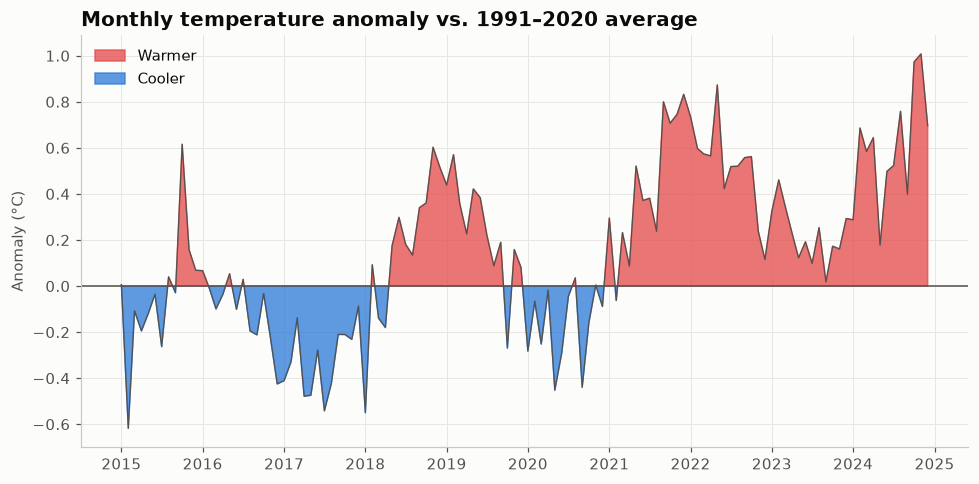

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x, y = df["date"], df["anomaly"]
ax.fill_between(x, y, 0, where=y >= 0, interpolate=True, color=PALETTE[7], alpha=0.75, label="Warmer")
ax.fill_between(x, y, 0, where=y < 0, interpolate=True, color=PALETTE[0], alpha=0.75, label="Cooler")
ax.plot(x, y, color="#52514e", linewidth=0.8)
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_ylabel("Anomaly (°C)")
ax.set_title("Monthly temperature anomaly vs. 1991–2020 average")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## How to read it

Red areas show months warmer than average and blue areas cooler. The shift from mostly blue to mostly red shows the warming trend.

---
Standalone script: [`surplus_deficit_line.py`](surplus_deficit_line.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)